## CMF-BO-GP 8.1

### Function 8 - EIGHT 

Optimising an eight-dimensional black-box function, where each of the eight input parameters affects the output, but the internal mechanics are unknown. 
Your objective is to find the parameter combination that maximises the function’s output, such as performance, efficiency or validation accuracy. Because the function is high-dimensional and likely complex, global optimisation is hard, so identifying strong local maxima is often a practical strategy.


 ### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [5]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [10]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# Load 8D spatial coordinate data and output values
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC8/initial_inputs.npy')
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC8/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.114880, 0.178555, 0.075273, 0.000000, 0.916081, 0.262592, 0.060060, 0.559467]
                ,[0.000001, 0.000001, 0.000001, 0.999999, 0.999999, 0.999999, 0.000001, 0.000001]
                ,[0.000000, 0.399074, 0.123214, 0.112487, 0.679719, 0.634021, 0.180101, 0.801376]
                ,[0.292167, 0.239996, 0.000000, 0.200878, 0.739206, 0.000000, 0.179025, 0.000000]
                ,[0.192904, 0.000000, 0.150536, 0.000000, 0.505509, 0.000000, 0.214491, 1.000000]
                ,[0.000000, 0.000000, 0.277294, 0.000000, 1.000000, 0.663569, 0.261522, 0.752310]
                ,[0.000000, 0.176928, 0.211399, 0.000000, 0.511120, 0.577279, 0.041490, 0.000000]
                ,[0.014304, 0.215537, 0.184355, 0.000000, 0.649437, 0.515553, 0.233621, 0.472100]
                ,[0.001000, 0.219591, 0.001000, 0.000000, 0.860139, 0.520245, 0.194834, 0.546817]
                ,[0.216174, 0.000001, 0.000001, 0.869640, 0.522139, 0.196805, 0.537216, 0.000000]
                ,[0.058972, 0.225764, 0.148112, 0.002111, 0.864007, 0.530050, 0.194249, 0.521492]
                ,[0.060987, 0.226008, 0.148539, 0.004921, 0.868762, 0.531293, 0.194660, 0.519577]
]

extra_output = [9.8648259922346,8.7983052999894,9.8863742103059,
                9.576027980854,9.6266900589775,9.813268868353,
               9.802948779972,9.9341808061485,9.9005776647726,
               8.9879667168465,9.9644039836501,9.9650525805301]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: ",output.max())


# Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_S','Input_T','Input_U','Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'])
df['Output_Target'] = output

# Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_S','Input_T','Input_U','Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")


# Fit a quick non-linear model that checks all 4 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_S','Input_T','Input_U','Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia:  9.598482002566342
Current Maxima:  9.9650525805301
Correlation with Output:
Input_S   -0.758714
Input_T   -0.424949
Input_U   -0.734893
Input_V   -0.358570
Input_W    0.189279
Input_X    0.027551
Input_Y   -0.559932
Input_Z    0.007530
Name: Output_Target, dtype: float64
Input_S Mutual Information Score: 0.4454
Input_T Mutual Information Score: 0.2055
Input_U Mutual Information Score: 0.4299
Input_V Mutual Information Score: 0.2071
Input_W Mutual Information Score: 0.0000
Input_X Mutual Information Score: 0.1131
Input_Y Mutual Information Score: 0.2917
Input_Z Mutual Information Score: 0.0215
Input_S Total Importance (with interactions): 0.3859
Input_T Total Importance (with interactions): 0.0169
Input_U Total Importance (with interactions): 0.3709
Input_V Total Importance (with interactions): 0.0821
Input_W Total Importance (with interactions): 0.0235
Input_X Total Importance (with interactions): 0.0138
Input_Y Total Importance (with interactions): 0.0902
Input_Z Total 

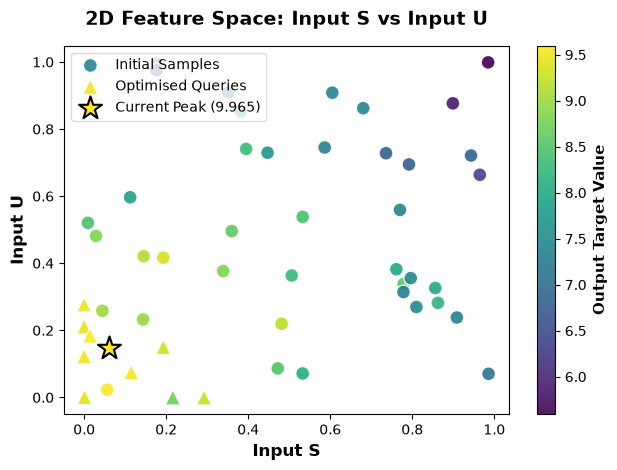

In [11]:
# ===================================
# 3.1 Visualise the data set S and U
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_S']
max_z = df.loc[max_row_index, 'Input_U']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 30 smaples
scatter1 = plt.scatter(
    data=df.iloc[:40], 
    x='Input_S', 
    y='Input_U', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[40:len(output)], 
    x='Input_S', 
    y='Input_U', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input S', fontsize=12, fontweight='bold')
plt.ylabel('Input U', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input S vs Input U', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

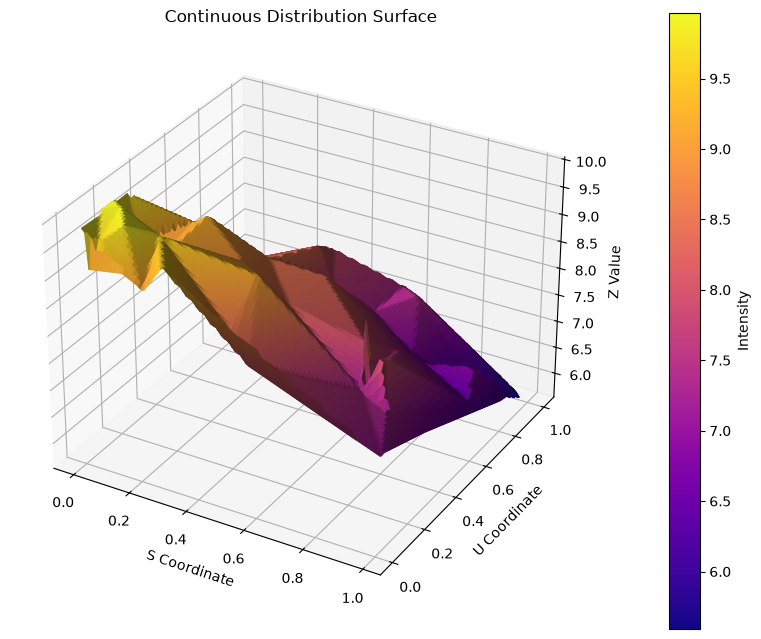

In [12]:
# ===================================
# 3.2. Visualise the data set 3D
# ===================================

coords = (inputs[:,0],inputs[:,2])

# Define a regular 2D grid based on your data boundaries
grid_x, grid_y = np.meshgrid(
    np.linspace(coords[0].min(), coords[0].max(), 100),
    np.linspace(coords[1].min(), coords[1].max(), 100)
)

# Interpolate the scattered (x, y, z) data onto the uniform grid
# Options for method: 'linear', 'cubic', or 'nearest'
grid_z = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# If your y_clean variable is different from values, interpolate it too for the colors
grid_color = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# Create the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

norm = colors.Normalize(vmin=output.min(), vmax=output.max())

# Plot the continuous surface
# facecolors overrides standard mapping to use your output
surf = ax.plot_surface(
    grid_x, grid_y, grid_z,
    facecolors=plt.cm.plasma(norm(grid_color)),
    rcount=100, ccount=100,  # Grid resolution
    antialiased=True,
    shade=True
)

# Design elements
# Create a dummy scalar mappable object just to display the colorbar correctly
mappable = plt.cm.ScalarMappable(cmap='plasma', norm = colors.Normalize(vmin=output.min(), vmax=output.max()))
fig.colorbar(mappable, ax=ax, label="Intensity", pad=0.1)

ax.set_xlabel("S Coordinate")
ax.set_ylabel("U Coordinate")
ax.set_zlabel("Z Value")
ax.set_title("Continuous Distribution Surface")

plt.show()


In [13]:
# ===========================================
# 4 (v1) GP Model - with UCB/EI 
# ===========================================

import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train a predictive model on your 40 existing samples
predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_8D(X):
    """
    Surrogate function for 8D optimization.
    X: A 2D numpy array of shape (n_samples, 5) sent by the optimizer.
    """
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    return predictions.ravel()

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern,ConstantKernel as C
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

In [15]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=1, 
                            n_initial=1, acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output

    initial_length_scales = np.array([
        0.15,  # Input_S: Hyper-critical core control -> High Priority
        3.00,  # Input_T: Passenger parameter -> Filtered out
        0.12,  # Input_U: Absolute dominant core control -> Highest Priority
        3.00,  # Input_V: Passenger parameter -> Filtered out
        3.00,  # Input_W: Passenger parameter -> Filtered out
        3.00,  # Input_X: Passenger parameter -> Filtered out
        0.40,  # Input_Y: Non-linear regulator -> Medium Priority
        3.00   # Input_Z: Passenger parameter -> Filtered out
    ])
    length_scale_bounds = [(1e-2, 1e2) for _ in range(n_dims)]

    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")
  
    
    for iteration in range(n_iterations):
        # Fit GP
        kernel = C(1.0, (1e-3, 1e3)) * Matern(
        length_scale=initial_length_scales.copy(), # .copy() avoids state contamination
        length_scale_bounds=length_scale_bounds,
        nu=2.5
        )
        gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,normalize_y=True,
                                     n_restarts_optimizer=10)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max(),xi=0.05)
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=1.0)
           
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
        X_next = None
        
        for _ in range(100):  # More starts for higher dimensions
            x0 = np.random.uniform(0, 1, n_dims)
            result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")

       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
    return X_samples, y_samples, best_values



# Run 8D optimization
X_samples_8d, y_samples_8d, best_values_8d = bayesian_optimization_nd(
    objective_8D, 
    n_dims=8,
    n_iterations=3,
    acquisition='ei'
)


Starting 8D optimization with 1 initial samples...
Initial best: 9.9651

Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.98193508 0.00873941 0.26807913 0.23510628 0.49095051 0.83467857
 0.34457308 0.95014889]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.3913564  0.02294236 0.09382538 0.88124241 0.23761099 0.6389753
 0.18503125 0.71837761]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.03186838 0.87765504 0.01437325 0.68053264 0.98041574 0.3530674
 0.46451594 0.21544944]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.17810604 0.42499296 0.0734117  0.01223246 0.79629812 0.35450662
 0.03230824 0.63307463]
Optimized Next Point Found! Predicted Acquisition Score: 0.000000
Coordinates to test next: [0.83888857 0.50310973 0.83206936 0.08146336 0.04441204 0.93954091
 0.73947562 0.74534643]
Optimized Next

In [18]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize


X_train = inputs
y_train = output

# Anisotropic length scales (1 per dimension) allow the model to learn that 
# S and U have extreme, sharp cliffs while W, X, and Z are highly flat.
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(8), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)
gp.fit(X_train, y_train)

# Define objective (minimize the negative prediction to maximize output)
def objective(x):
    return -gp.predict(x.reshape(1, -1))[0]

  
bounds = [
        (0.0, 0.25),  # Input_S: Hard pinned to zero ceiling
        (0.2, 0.5),    # Input_T: Low-to-mid range
        (0.0, 0.25),  # Input_U: Hard pinned to zero ceiling
        (0.000001, 0.35),  # Input_V: Low-to-mid range
        (0.5, 1.0),    # Input_W: Neutral mid-tier bracket
        (0.4, 0.6),    # Input_X: Neutral mid-tier bracket
        (0.0, 0.3),   # Input_Y: Kept strictly low
        (0.4, 0.6)     # Input_Z: Neutral mid-tier bracket
    ]

# Warm-start point for the local L-BFGS-B search engine
best_idx = np.argmax(y_train)
x_start = X_train[best_idx]

# Execute Gradient Optimization Pass over the surrogate landscape
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)
x_optimum = result.x
predicted_val = f"{abs(result.fun):.4f}"

# ==========================================
# 4. PRINT PREDICTED OPTIMAL COORDINATES
# ==========================================
print("\n--- 8D BLACK BOX SURROGATE PREDICTION ---")
print(f"Predicted Max Output: {predicted_val}")
print("Optimal Vector Configurations to Run:")
for name, val in zip(['S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'], x_optimum):
    print(f"  Input_{name}: {val:.6f}")


--- 8D BLACK BOX SURROGATE PREDICTION ---
Predicted Max Output: 9.9665
Optimal Vector Configurations to Run:
  Input_S: 0.075462
  Input_T: 0.223389
  Input_U: 0.152773
  Input_V: 0.040918
  Input_W: 0.886462
  Input_X: 0.529758
  Input_Y: 0.202921
  Input_Z: 0.500954
